=== DATA QUALITY LOG ===
                 Check Step                                                     Cleaning Rule  Before  After  Removed
    1. Technical Test Cases              Exclude Case IDs starting with 'T-' (T-001 to T-005)      36     31        5
    2. Case ID & Duplicates Match valid S-/C- pattern and drop duplicate C-M-006 (keep first)      31     30        1
      3. Consent & Age Gate                 Keep Consent=YES and Age 18-110 (removes C-F-007)      30     29        1
4. Skip Logic & Consistency        Fix S-F-008 sex label; recode non-drinkers to Inapplicable      29     29        0

=== BENCHMARK TABLE (FOR POWER BI RECONCILIATION) ===
 Domain  Valid_Adults  Ind1_Drinkers_Count  Ind1_Denom  Ind1_Prevalence_Pct  Ind2_Binge_Count  Ind2_Binge_Denom  Ind2_Binge_Pct  Ind3_Beer_Count  Ind3_Beer_Denom  Ind3_Beer_Pct
Overall            29                   20          29                68.97                14                17           82.35                8         

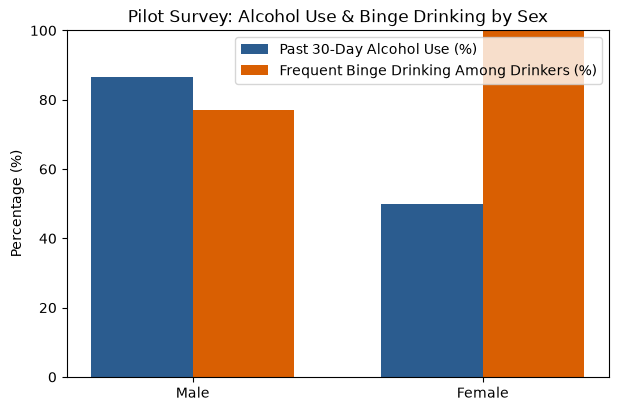

<Figure size 640x480 with 0 Axes>

Saved clean_case_level.csv and benchmark_table.csv successfully!


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../exports", exist_ok=True)

# 1. Load Raw CSV
raw_path = "raw-export.csv.csv"

df_raw = pd.read_csv(raw_path)

# Clean column headers
df_raw.columns = [c.strip().replace("\n", " ") for c in df_raw.columns]

rename_dict = {}
for col in df_raw.columns:
    if col.startswith("Timestamp"):
        rename_dict[col] = "timestamp"
    elif col.startswith("Do you agree to take part"):
        rename_dict[col] = "consent"
    elif col.startswith("Case ID"):
        rename_dict[col] = "case_id"
    elif col.startswith("Source of this record"):
        rename_dict[col] = "record_source"
    elif col.startswith("What is your sex"):
        rename_dict[col] = "sex"
    elif col.startswith("Age in years"):
        rename_dict[col] = "age"
    elif col.startswith("In the last 30 days, did you drink"):
        rename_dict[col] = "drank_30d"
    elif col.startswith("Which kinds of alcohol"):
        rename_dict[col] = "alcohol_types"
    elif col.startswith("In the last 30 days, on how many days"):
        rename_dict[col] = "binge_days"
    elif col.startswith("Do you drink alcohol"):
        rename_dict[col] = "ever_drink_dup"
    elif col.startswith("Are you above 18"):
        rename_dict[col] = "above_18"

df = df_raw.rename(columns=rename_dict).copy()

for c in ["consent", "case_id", "record_source", "sex", "drank_30d", "alcohol_types", "binge_days", "above_18"]:
    if c in df.columns:
        df[c] = df[c].astype(str).str.strip().replace({"nan": np.nan, "": np.nan})

# ==============================================================================
# 2a) QUALITY CHECKS & LOGGING
# ==============================================================================
quality_log = []
def add_log(step, rule, before, after):
    quality_log.append({
        "Check Step": step,
        "Cleaning Rule": rule,
        "Before": before,
        "After": after,
        "Removed": before - after
    })

# Check 1: Remove technical test cases (T-001 to T-005)
n0 = len(df)
df1 = df[~df["case_id"].str.startswith("T-", na=False)].copy()
add_log("1. Technical Test Cases", "Exclude Case IDs starting with 'T-' (T-001 to T-005)", n0, len(df1))

# Check 2: Validate Case ID pattern & remove duplicate Case IDs (removes duplicate C-M-006)
n1 = len(df1)
pattern = r"^(S-M-00[1-7]|S-F-00[1-8]|C-M-00[1-8]|C-F-00[1-7])$"
df2 = df1[df1["case_id"].str.match(pattern, na=False)].drop_duplicates(subset=["case_id"], keep="first").copy()
add_log("2. Case ID & Duplicates", "Match valid S-/C- pattern and drop duplicate C-M-006 (keep first)", n1, len(df2))

# Check 3: Consent & Age >= 18 Gate (removes non-consenting C-F-007)
n2 = len(df2)
df2["age"] = pd.to_numeric(df2["age"], errors="coerce")
df3 = df2[
    (df2["consent"].str.upper() == "YES") &
    (df2["age"].between(18, 110)) &
    (df2["above_18"].isna() | (df2["above_18"].str.upper() == "YES"))
].copy()
add_log("3. Consent & Age Gate", "Keep Consent=YES and Age 18-110 (removes C-F-007)", n2, len(df3))

# Check 4: Standardize Labels, Fix Domain Mismatch (S-F-008), & Enforce Skip Logic
df_clean = df3.copy()
df_clean["record_source"] = df_clean["record_source"].replace({"Simulated response": "Simulated Household Response"})

# Align S-F-008 sex to Female to match its assigned Female Case ID prefix
df_clean["sex"] = np.where(df_clean["case_id"].str.contains("-F-"), "Female", "Male")

if "ever_drink_dup" in df_clean.columns:
    df_clean = df_clean.drop(columns=["ever_drink_dup"])

is_drinker = df_clean["drank_30d"].str.lower() == "yes"
for col in ["alcohol_types", "binge_days"]:
    df_clean[col] = np.where(~is_drinker, "Inapplicable", df_clean[col].fillna("Missing"))
    df_clean[col] = df_clean[col].replace({"Prefer not to say": "Refused", "Don't know": "Unknown"})

add_log("4. Skip Logic & Consistency", "Fix S-F-008 sex label; recode non-drinkers to Inapplicable", len(df3), len(df_clean))

quality_log_df = pd.DataFrame(quality_log)
print("=== DATA QUALITY LOG ===")
print(quality_log_df.to_string(index=False))


# ==============================================================================
# 2b) INDICATORS & BENCHMARK TABLE (OVERALL & BY SEX DOMAIN)
# ==============================================================================
df_clean["ind1_drinker"] = np.where(df_clean["drank_30d"] == "Yes", 1,
                           np.where(df_clean["drank_30d"] == "No", 0, np.nan))

valid_binge = (df_clean["drank_30d"] == "Yes") & (~df_clean["binge_days"].isin(["Inapplicable", "Refused", "Unknown", "Missing"]))
df_clean["elig_ind2"] = valid_binge
df_clean["ind2_frequent_binge"] = np.where(~valid_binge, np.nan,
                                  np.where(df_clean["binge_days"].isin(["5-10", "10-20", "20-30"]), 1, 0))

valid_type = (df_clean["drank_30d"] == "Yes") & (~df_clean["alcohol_types"].isin(["Inapplicable", "Refused", "Unknown", "Missing"]))
df_clean["elig_ind3"] = valid_type
df_clean["ind3_comm_beer"] = np.where(~valid_type, np.nan,
                             np.where(df_clean["alcohol_types"].str.contains("Commercial Beer", case=False, na=False), 1, 0))

def calc_metrics(sub_df, label):
    i1 = sub_df["ind1_drinker"].dropna()
    i2 = sub_df["ind2_frequent_binge"].dropna()
    i3 = sub_df["ind3_comm_beer"].dropna()
    return pd.Series({
        "Domain": label,
        "Valid_Adults": len(sub_df),
        "Ind1_Drinkers_Count": int(i1.sum()),
        "Ind1_Denom": int(len(i1)),
        "Ind1_Prevalence_Pct": round(i1.mean() * 100, 2) if len(i1) > 0 else np.nan,
        "Ind2_Binge_Count": int(i2.sum()),
        "Ind2_Binge_Denom": int(len(i2)),
        "Ind2_Binge_Pct": round(i2.mean() * 100, 2) if len(i2) > 0 else np.nan,
        "Ind3_Beer_Count": int(i3.sum()),
        "Ind3_Beer_Denom": int(len(i3)),
        "Ind3_Beer_Pct": round(i3.mean() * 100, 2) if len(i3) > 0 else np.nan
    })

benchmark_df = pd.DataFrame([
    calc_metrics(df_clean, "Overall"),
    calc_metrics(df_clean[df_clean["sex"] == "Male"], "Male"),
    calc_metrics(df_clean[df_clean["sex"] == "Female"], "Female")
])
print("\n=== BENCHMARK TABLE (FOR POWER BI RECONCILIATION) ===")

# Chart answering survey question
print(benchmark_df.to_string(index=False))
plot_df = benchmark_df[benchmark_df["Domain"].isin(list(("Male", "Female")))]
x = np.arange(len(plot_df["Domain"]))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width/2, plot_df["Ind1_Prevalence_Pct"], width, label="Past 30-Day Alcohol Use (%)", color="#2b5c8f")
ax.bar(x + width/2, plot_df["Ind2_Binge_Pct"], width, label="Frequent Binge Drinking Among Drinkers (%)", color="#d95f02")
ax.set_ylabel("Percentage (%)")
ax.set_title("Pilot Survey: Alcohol Use & Binge Drinking by Sex")
ax.set_xticks(x)
ax.set_xticklabels(plot_df["Domain"])
ax.set_ylim(0, 100)
ax.legend()
# Export CSVs immediately before showing chart
df_clean.to_csv("clean_case_level.csv", index=False)
benchmark_df.to_csv("benchmark_table.csv", index=False)
print("SUCCESS: clean_case_level.csv and benchmark_table.csv created!")
plt.show()
plt.tight_layout()
plt.show()

# ==============================================================================
# 2c) SEPARATE PROBABILITY WEIGHTING DEMONSTRATION
# ==============================================================================
sim_strata = pd.DataFrame({
    "Stratum": list(("Urban (Harare/Bulawayo)", "Rural (Mashonaland/Matabeleland)")),
    "Pop_Adults_N": list((2500000, 5500000)),
    "Sample_n": list((400, 400)),
    "Observed_Drinkers": list((240, 150))
})



sim_strata["Selection_Prob"] = sim_strata["Sample_n"] / sim_strata["Pop_Adults_N"]
sim_strata["Base_Weight"] = 1 / sim_strata["Selection_Prob"]

unweighted = sim_strata["Observed_Drinkers"].sum() / sim_strata["Sample_n"].sum()
weighted = np.sum(sim_strata["Base_Weight"] * sim_strata["Observed_Drinkers"]) / np.sum(sim_strata["Base_Weight"] * sim_strata["Sample_n"])
df_clean.to_csv("clean_case_level.csv", index=False)
benchmark_df.to_csv("benchmark_table.csv", index=False)
print("Saved clean_case_level.csv and benchmark_table.csv successfully!")
benchmark_df.to_csv("../data/processed/benchmark_table.csv",)

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create output folder for all 10 analysis files
out_dir = "analysis_outputs"
os.makedirs(out_dir, exist_ok=True)

# Load your cleaned dataset
df = pd.read_csv("clean_case_level.csv")

# ==============================================================================
# 1. GENERATE THE 4 CSV SUMMARY TABLES
# ==============================================================================
# 1a) category_counts.csv
cat_rows = list()
for col in list(("sex", "record_source", "drank_30d", "binge_days")):
    vc = df[col].fillna("Missing").value_counts()
    for val, cnt in vc.items():
        cat_rows.append({"Variable": col, "Category": val, "Count": int(cnt), "Pct": round(cnt / len(df) * 100, 2)})
category_counts_df = pd.DataFrame(cat_rows)
category_counts_df.to_csv(os.path.join(out_dir, "category_counts.csv"), index=False)

# 1b) drinking_by_sex.csv
drinking_by_sex = df.groupby("sex").agg(
    Total_Adults=("case_id", "count"),
    Drinkers=("ind1_drinker", "sum"),
    Prevalence_Pct=("ind1_drinker", lambda s: round(s.mean() * 100, 2))
).reset_index()
drinking_by_sex.to_csv(os.path.join(out_dir, "drinking_by_sex.csv"), index=False)

# 1c) drinking_by_source.csv
drinking_by_source = df.groupby("record_source").agg(
    Total_Adults=("case_id", "count"),
    Drinkers=("ind1_drinker", "sum"),
    Prevalence_Pct=("ind1_drinker", lambda s: round(s.mean() * 100, 2))
).reset_index()
drinking_by_source.to_csv(os.path.join(out_dir, "drinking_by_source.csv"), index=False)

# 1d) heavy_drinking_by_source.csv (among eligible current drinkers)
drinkers_only = df[df["elig_ind2"] == True]
heavy_by_source = drinkers_only.groupby("record_source").agg(
    Eligible_Drinkers=("case_id", "count"),
    Frequent_Binge_Count=("ind2_frequent_binge", "sum"),
    Frequent_Binge_Pct=("ind2_frequent_binge", lambda s: round(s.mean() * 100, 2))
).reset_index()
heavy_by_source.to_csv(os.path.join(out_dir, "heavy_drinking_by_source.csv"), index=False)

# ==============================================================================
# 2. GENERATE THE 5 PNG CHARTS
# ==============================================================================
# 2a) age_distribution.png
plt.figure(figsize=(7, 4.5))
for sex_label, color in list((("Male", "#2b5c8f"), ("Female", "#d95f02"))):
    subset = df[df["sex"] == sex_label]["age"].dropna()
    plt.hist(subset, bins=6, alpha=0.65, label=sex_label, color=color, edgecolor="black")
plt.title("Age Distribution of Valid Respondents by Sex")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Respondents")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "age_distribution.png"), dpi=150)
plt.close()

# 2b) alcohol_last_30_days.png
plt.figure(figsize=(7, 4.5))
ct_drink = pd.crosstab(df["sex"], df["drank_30d"])
ct_drink.plot(kind="bar", color=list(("#d95f02", "#2b5c8f")), edgecolor="black", ax=plt.gca())
plt.title("Past 30-Day Alcohol Consumption by Sex")
plt.xlabel("Sex (Reporting Domain)")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=0)
plt.legend(title="Drank in Last 30 Days")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "alcohol_last_30_days.png"), dpi=150)
plt.close()

# 2c) alcohol_types.png (split multi-select answers among drinkers)
valid_types = df[df["elig_ind3"] == True]["alcohol_types"].dropna()
type_series = valid_types.str.split(",").explode().str.strip()
type_counts = type_series.value_counts()

plt.figure(figsize=(8, 4.5))
type_counts.plot(kind="bar", color="#1b9e77", edgecolor="black")
plt.title("Alcoholic Beverage Types Consumed (Past 30 Days)")
plt.xlabel("Beverage Category")
plt.ylabel("Mentions Among Eligible Drinkers")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "alcohol_types.png"), dpi=150)
plt.close()

# 2d) heavy_drinking_days.png
valid_binge_df = df[df["drank_30d"] == "Yes"]
binge_counts = valid_binge_df["binge_days"].value_counts()

plt.figure(figsize=(7.5, 4.5))
binge_counts.plot(kind="bar", color="#7570b3", edgecolor="black")
plt.title("Frequency of Heavy Drinking (6+ Drinks) Among Current Drinkers")
plt.xlabel("Days in Past 30 Days")
plt.ylabel("Number of Current Drinkers")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "heavy_drinking_days.png"), dpi=150)
plt.close()

# 2e) records_by_source.png
source_sex = pd.crosstab(df["record_source"], df["sex"])
plt.figure(figsize=(7, 4.5))
source_sex.plot(kind="bar", stacked=True, color=list(("#e7298a", "#2b5c8f")), edgecolor="black", ax=plt.gca())
plt.title("Valid Pilot Records by Source Type and Sex")
plt.xlabel("Record Source")
plt.ylabel("Number of Valid Records")
plt.xticks(rotation=15, ha="right")
plt.legend(title="Sex")
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "records_by_source.png"), dpi=150)
plt.close()

# ==============================================================================
# 3. GENERATE THE TEXT SUMMARY REPORT (eda_report.txt)
# ==============================================================================
report_lines = list((
    "============================================================",
    "HASTS206 EXPLORATORY DATA ANALYSIS (EDA) SUMMARY REPORT",
    "Topic: Alcohol Consumption Patterns by Sex in Zimbabwe",
    "============================================================\n",
    f"Total Valid Consenting Adults Analyzed: {len(df)}",
    f"Mean Age: {df['age'].mean():.1f} years (Min: {df['age'].min():.0f}, Max: {df['age'].max():.0f})\n",
    "--- 1. DRINKING PREVALENCE BY SEX ---",
    drinking_by_sex.to_string(index=False),
    "\n--- 2. DRINKING PREVALENCE BY SOURCE ---",
    drinking_by_source.to_string(index=False),
    "\n--- 3. FREQUENT BINGE DRINKING BY SOURCE ---",
    heavy_by_source.to_string(index=False),
    "\n--- 4. BEVERAGE MENTIONS AMONG DRINKERS ---",
    type_counts.to_string()
))

with open(os.path.join(out_dir, "eda_report.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))

print(f"SUCCESS: All 10 analysis files created inside '{out_dir}/'!")

SUCCESS: All 10 analysis files created inside 'analysis_outputs/'!
